# Curso de Inteligencia Artificial
## 5.8 Repaso del capítulo

### <font color='purple'> Alumno: ____________________________</font>
### <font color='blue'> Profesor: Alejandro Ismael Trejo Castro</font>

**Objetivo:** Entrenar y comparar dos modelos de machine learning, realizar una búsqueda de hiperparámetros e interpretar su desempeño mediante métricas y gráficas.

**Datos:** Breast Cancer Wisconsin, disponible en scikit-learn. Contiene 569 muestras y 30 variables predictoras numéricas. El propósito es clasificar muestras como beningnas o malignas.

**Selecciona dos modelos diferentes entre las siguientes opciones:**
- `Regresión logística`
- `Árbol de decisión`
- `KNN`
- `SVM`
- `Naive Bayes gaussiano`

### 1. Importación de librerías

In [1]:
# Cargar y explorar el dataset
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer

# Dividir los datos en entrenamiento y prueba
from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    StratifiedKFold
)

# Estandarizar variables
from sklearn.preprocessing import StandardScaler

# Construir los modelos
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

# Clcular métricas
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

### 2. Carga del dataset

Carguen el dataset mediante `load_breast_cancer(as_frame=True)`.

Definan:

- `X`: variables predictoras.
- `y`: variable objetivo.

- **0 = benigno.**
- **1 = maligno.**

De esta manera, la clase maligna será la clase positiva al calcular
precisión, sensibilidad y F1.

Construyan un DataFrame que incluya las variables predictoras y
la variable objetivo. Muestren sus primeras cinco filas mediante
`.head()`.

In [2]:
datos = load_breast_cancer(as_frame=True)

X = datos.data

y = (datos.target == 0).astype(int)
y.name = "maligno"

df = X.copy()
df["maligno"] = y

display(df.head())

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,maligno
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1


### 3. Exploración inicial

Identificar:
- `a.` El número de muestras
- `b.` El número de variables predictoras
- `c.` Los tipos de datos
- `d.` La presencia o ausencia de valores faltantes
- `e.` La cantidad de muestras de cada clase
- `f.` Las estadísticas descriptivas de las variables predictoras

.shape, .info(), .isna().sum(), .value_counts(), .describe(), etc...

In [3]:
df.shape

(569, 31)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         569 non-null

In [5]:
df.isna().sum()

mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
maligno                    0
dtype: int64

In [6]:
df.maligno.value_counts()

maligno
0    357
1    212
Name: count, dtype: int64

In [7]:
df.describe()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,maligno
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,0.372583
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,0.483918
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,0.000000
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,0.000000
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,0.000000
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,1.000000
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,1.000000


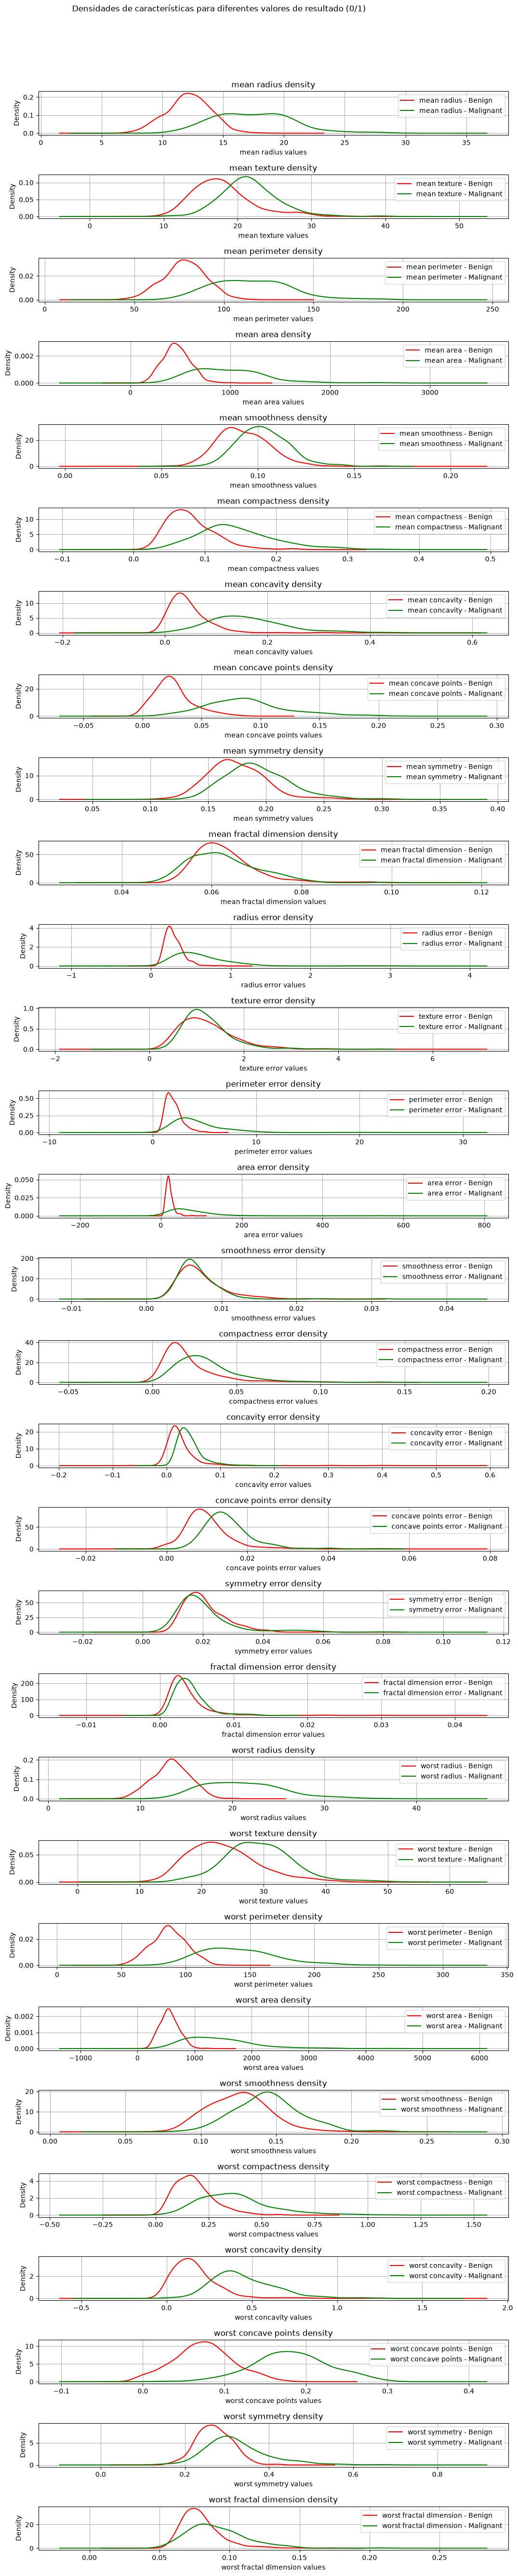

In [8]:
from pylab import rcParams

def plot_densities(data):
    '''
    Plot features densities depending on the outcome values
    '''
    # Cambiar el tamaño de la figura para ajustar los subgráficos
    rcParams['figure.figsize'] = 15, 60

    # Separar los datos según el valor de la variable objetivo (target)
    outcome_0 = data[data['maligno'] == 0]
    outcome_1 = data[data['maligno'] == 1]

    # Obtener los nombres de las características excluyendo la columna 'target'
    names = data.columns[:-1]

    # Inicializar la figura con subgráficos
    fig, axs = plt.subplots(len(names), 1)
    fig.suptitle('Densidades de características para diferentes valores de resultado (0/1)')
    plt.subplots_adjust(left=0.25, right=0.9, bottom=0.1, top=0.95,
                        wspace=0.2, hspace=0.9)

    # Graficar las densidades para cada característica
    for idx, column_name in enumerate(names): 
        ax = axs[idx]
        outcome_0[column_name].plot(kind='density', ax=ax, subplots=True, 
                                    sharex=False, color="red", legend=True,
                                    label=column_name + ' - Benign')
        outcome_1[column_name].plot(kind='density', ax=ax, subplots=True, 
                                    sharex=False, color="green", legend=True,
                                    label=column_name + ' - Malignant')
        ax.set_xlabel(column_name + ' values')
        ax.set_title(column_name + ' density')
        ax.grid(True)

    plt.show()
    fig.savefig('densities.png')

# Ejecutar la función para visualizar las densidades
plot_densities(df)

#### 4. División en entrenamiento y prueba

Dividir los datos mediante "train_test_split()":

- `70% entrenamiento`
- `30% prueba`

Recomendación: stratify, random_state y que ambos modelos tengan exactamente la misma partición.


In [9]:
from sklearn.model_selection import train_test_split
train, test = train_test_split(df, stratify=df.maligno ,train_size = 0.7, random_state=42)

X_train = train.drop('maligno', axis = 1)
Y_train = train.maligno
X_test = test.drop('maligno', axis = 1)
Y_test = test.maligno

# Imprime dimensiones de datos de entrenamiento
print("Train:", train.shape)
# Imprime dimensiones de datos de prueba
print("Test:",test.shape)

total_observations = train.shape[0] + test.shape[0]
print("Total de observaciones en ambos conjuntos:", total_observations)
print("Observaciones originales en el DataFrame:", df.shape[0])

Train: (398, 31)
Test: (171, 31)
Total de observaciones en ambos conjuntos: 569
Observaciones originales en el DataFrame: 569


In [10]:
pd.DataFrame({
    "Entrenamiento": Y_train.value_counts(),
    "Prueba": Y_test.value_counts()})

,Entrenamiento,Prueba
maligno,,
0,250,107
1,148,64


### 5. Selección de modelos y definición de hiperparámetros

Seleccionen dos modelos diferentes de la siguiente tabla.
Exploren los valores propuestos.

| Modelo | Clase de scikit-learn | Hiperparámetros |
|---|---|---|
| Regresión logística | `LogisticRegression(max_iter=2000)` | `C`: `[0.01, 0.1, 1, 10]` |
| Árbol de decisión | `DecisionTreeClassifier(random_state=42)` | `max_depth`: `[2, 4, 6, None]`; `min_samples_leaf`: `[1, 3, 5]` |
| KNN | `KNeighborsClassifier()` | `n_neighbors`: `[3, 5, 7, 11]`; `weights`: `['uniform', 'distance']` |
| SVM | `SVC()` | `C`: `[0.1, 1, 10]`; `kernel`: `['linear', 'rbf']` |
| GaussianNB | `GaussianNB()` | `var_smoothing`: `[1e-11, 1e-9, 1e-7, 1e-5]` |

#### Preprocesamiento

Para regresión logística, KNN y SVM, estandaricen las variables con `StandardScaler()`.
El árbol de decisión y GaussianNB pueden utilizarse sin escalamiento en esta actividad.

**No estandaricen todo el dataset antes de dividirlo.**

In [11]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### 6. Búsqueda de hiperparámetros

Utilicen `GridSearchCV()` para buscar la mejor combinación de hiperparámetros de cada modelo.

Configuren una validación cruzada estratificada de cinco particiones mediante:

`StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`

Utilicen: - `scoring='roc_auc'`: seleccionar mediante el área bajo la curva ROC.

Reporten:

1. Los mejores hiperparámetros: `.best_params_`.
2. El ROC-AUC promedio de validación cruzada: `.best_score_`.

El mejor modelo entrenado se encuentra en `.best_estimator_`.

**Recuerden:** la validación cruzada ocurre dentro del 70% de entrenamiento. El 30% de prueba permanece reservado.

#### Árbol de decisión

In [12]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV

# Define the parameter grid
param_grid = {
    'max_depth': [2, 4, 6, None], 
    'min_samples_leaf': [1, 3, 5]
}

# Create a Decision Tree model
dtree_model = DecisionTreeClassifier(random_state=42)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Use GridSearchCV to test all combinations with 5-fold cross-validation (cv=5)
grid_search = GridSearchCV(
    estimator=dtree_model,
    param_grid=param_grid,
    cv=skf,
    scoring='roc_auc', # Or another appropriate metric
    verbose=1,
    n_jobs=-1 # Use all available cores
)

# Fit the GridSearchCV to the data
grid_search.fit(X_train,Y_train)

print ("Mean cross-validated score of the best_estimator: {}".format (grid_search.best_score_))
print ("best parameters: {}".format (grid_search.best_params_))
print ("best estimator: {}".format (grid_search.best_estimator_))

best = grid_search.best_estimator_  
y1 = best.predict(X_test)

Fitting 5 folds for each of 12 candidates, totalling 60 fits
Mean cross-validated score of the best_estimator: 0.9547080459770114
best parameters: {'max_depth': None, 'min_samples_leaf': 5}
best estimator: DecisionTreeClassifier(min_samples_leaf=5, random_state=42)


#### KNN

In [14]:
from sklearn.model_selection import GridSearchCV

# Define the parameter grid
param_grid = {
    'n_neighbors': [3, 5, 7, 11], 
    'weights': ['uniform', 'distance']
}

# Create a Decision Tree model
knn_model = KNeighborsClassifier()

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Use GridSearchCV to test all combinations with 5-fold cross-validation (cv=5)
grid_search = GridSearchCV(
    estimator=knn_model,
    param_grid=param_grid,
    cv=skf,
    scoring='roc_auc', # Or another appropriate metric
    verbose=1,
    n_jobs=-1 # Use all available cores
)

# Fit the GridSearchCV to the data
grid_search.fit(X_train_scaled,Y_train)

print ("Mean cross-validated score of the best_estimator: {}".format (grid_search.best_score_))
print ("best parameters: {}".format (grid_search.best_params_))
print ("best estimator: {}".format (grid_search.best_estimator_))

best = grid_search.best_estimator_  
y3 = best.predict(X_test_scaled)

Fitting 5 folds for each of 8 candidates, totalling 40 fits
Mean cross-validated score of the best_estimator: 0.987225287356322
best parameters: {'n_neighbors': 11, 'weights': 'distance'}
best estimator: KNeighborsClassifier(n_neighbors=11, weights='distance')


### 7. Predicción 

Calculen las siguientes métricas:

| Métrica | Función |
|---|---|
| Exactitud | `accuracy_score()` |
| Precisión | `precision_score()` |
| Sensibilidad o recall | `recall_score()` |
| F1 | `f1_score()` |
| Área bajo la curva ROC | `roc_auc_score()` |

La precisión, el recall y F1 deben corresponder a la clase
**1 = maligno**.

Para obtener las clases predichas, utilicen `.predict(X_test)`.

Para calcular el ROC-AUC:

- Utilicen `.predict_proba(X_test)[:, 1]` si el modelo ofrece
  probabilidades.
- Para `SVC()`, utilicen `.decision_function(X_test)`.

**No calculen el ROC-AUC utilizando las clases obtenidas
con `.predict()`.** Utilicen probabilidades o puntuaciones
continuas.


#### Árbol de decisión

In [15]:
import numpy as np
model = DecisionTreeClassifier(min_samples_leaf=5, random_state=42).fit(X_train,Y_train)

y2 = model.predict(X_test)
print(np.array_equal(y1, y2))  # True esperado

True


In [16]:
acc = accuracy_score(Y_test, y2)
prec = precision_score(Y_test, y2)     # o 'weighted'
rec  = recall_score(Y_test, y2)        # o 'weighted'
f1   = f1_score(Y_test, y2)            # o 'weighted'

print("Accuracy:", np.round(acc,2))
print("Precision:", np.round(prec,2))
print("Recall:", np.round(rec,2))
print("F1-score:", np.round(f1,2))

Accuracy: 0.9
Precision: 0.96
Recall: 0.77
F1-score: 0.85


AUC (modelo manual): 0.94


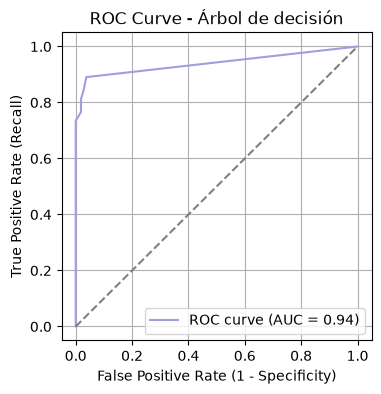

In [17]:
from sklearn.metrics import auc, roc_auc_score, roc_curve
y_proba = model.predict_proba(X_test)[:, 1]
auc = np.round(roc_auc_score(Y_test, y_proba),2)
print(f"AUC (modelo manual): {auc:.2f}")

fpr, tpr, thresholds = roc_curve(Y_test, y_proba)
plt.figure(figsize=(4, 4))
plt.plot(fpr, tpr, label=f'ROC curve (AUC = {auc:.2f})', color = '#9e9ee2')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Recall)')
plt.title('ROC Curve - Árbol de decisión')
plt.legend()
plt.grid()
plt.show()

In [18]:
from sklearn.metrics import classification_report
print(classification_report(Y_test, y2))

              precision    recall  f1-score   support

           0       0.88      0.98      0.93       107
           1       0.96      0.77      0.85        64

    accuracy                           0.90       171
   macro avg       0.92      0.87      0.89       171
weighted avg       0.91      0.90      0.90       171



#### KNN

In [20]:
import numpy as np
model = KNeighborsClassifier(n_neighbors=11, weights='distance').fit(X_train_scaled,Y_train)

y4 = model.predict(X_test_scaled)
print(np.array_equal(y3, y4))  # True esperado

True


In [21]:
acc = accuracy_score(Y_test, y4)
prec = precision_score(Y_test, y4)     # o 'weighted'
rec  = recall_score(Y_test, y4)        # o 'weighted'
f1   = f1_score(Y_test, y4)            # o 'weighted'

print("Accuracy:", np.round(acc,2))
print("Precision:", np.round(prec,2))
print("Recall:", np.round(rec,2))
print("F1-score:", np.round(f1,2))

Accuracy: 0.96
Precision: 0.98
Recall: 0.91
F1-score: 0.94


AUC (modelo manual): 1.00


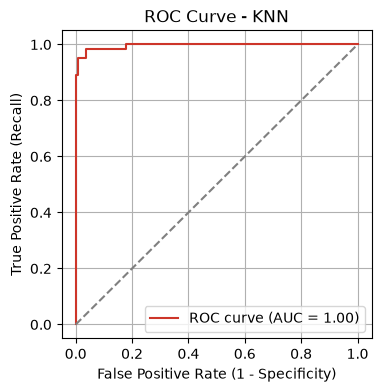

In [23]:
from sklearn.metrics import auc, roc_auc_score, roc_curve
y_proba = model.predict_proba(X_test_scaled)[:, 1]
auc = np.round(roc_auc_score(Y_test, y_proba),2)
print(f"AUC (modelo manual): {auc:.2f}")

fpr, tpr, thresholds = roc_curve(Y_test, y_proba)
plt.figure(figsize=(4, 4))
plt.plot(fpr, tpr, label=f'ROC curve (AUC = {auc:.2f})', color = '#CD3529')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Recall)')
plt.title('ROC Curve - KNN')
plt.legend()
plt.grid()
plt.show()

In [24]:
from sklearn.metrics import classification_report
print(classification_report(Y_test, y4))

              precision    recall  f1-score   support

           0       0.95      0.99      0.97       107
           1       0.98      0.91      0.94        64

    accuracy                           0.96       171
   macro avg       0.96      0.95      0.96       171
weighted avg       0.96      0.96      0.96       171



### 8. Matrices de confusión

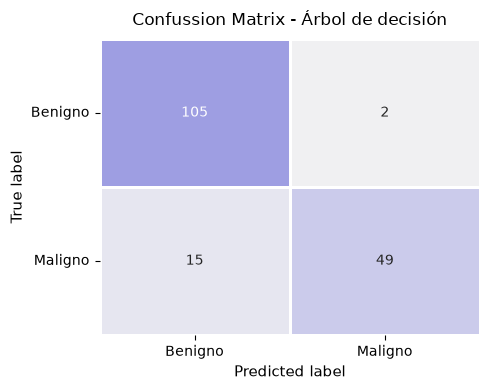

In [25]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
cm = confusion_matrix(Y_test, y2, labels=[0, 1])
labels_cute = ['Benigno', 'Maligno']

plt.style.use('default')
fig, ax = plt.subplots(figsize=(5, 4))


sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap=sns.light_palette("#9e9ee2", as_cmap=True),  # pastel verdoso
    cbar=False,
    linewidths=1,
    linecolor='white',
    xticklabels=labels_cute,
    yticklabels=labels_cute,
    ax=ax
)

ax.set_xlabel("Predicted label", fontsize=11)
ax.set_ylabel("True label", fontsize=11)
ax.set_title("Confussion Matrix - Árbol de decisión", fontsize=12, pad=10)

ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)

plt.tight_layout()
plt.show()

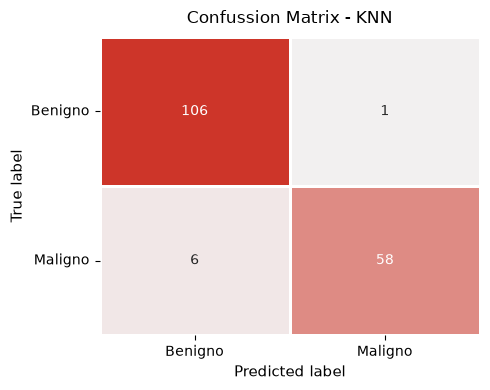

In [26]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
cm = confusion_matrix(Y_test, y4, labels=[0, 1])
labels_cute = ['Benigno', 'Maligno']

plt.style.use('default')
fig, ax = plt.subplots(figsize=(5, 4))


sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap=sns.light_palette("#CD3529", as_cmap=True),  # pastel verdoso
    cbar=False,
    linewidths=1,
    linecolor='white',
    xticklabels=labels_cute,
    yticklabels=labels_cute,
    ax=ax
)

ax.set_xlabel("Predicted label", fontsize=11)
ax.set_ylabel("True label", fontsize=11)
ax.set_title("Confussion Matrix - KNN", fontsize=12, pad=10)

ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)

plt.tight_layout()
plt.show()

#### 9. ¿Qué modelo seleccionarías y por qué?